# Is Each Model's Best Strategy *Significantly* Better Than Doing Nothing?

**The gap this fills**: every significance test built so far in this project (Friedman,
Wilcoxon, Nadeau-Bengio) compares **models against each other** at each model's best
strategy. None of them test whether a model's own improvement **over its own baseline**
is real. The paper's "Effects of class imbalance handling strategies" section currently
makes claims like *"Class Weights outperformed Original by 4.2 percentage points"* and
*"LightGBM improved from 0.770 (Original) to 0.804 (SMOTE)"* based only on the raw
10-seed means — those gaps have never been significance-tested. This notebook does that:
for each model, is its best strategy significantly better than its own Original
(no-resampling) baseline, across the same 10 seeds?

**Method**: same two tests already built and verified elsewhere in this project, just
paired along the *strategy* axis (Original vs. best-strategy, same model, same 10 seeds)
instead of the *model* axis (model A vs. model B, same strategy-selection rule):

1. **Wilcoxon signed-rank test** — non-parametric, makes no assumption about the shape
   of the improvement distribution. This is the same test used for the project's
   between-model comparisons.
2. **Nadeau-Bengio corrected t-test** — parametric but variance-corrected for the fact
   that the 10 seeds' train/test splits overlap (same correction, same justification,
   as `nadeau_bengio_ttest.ipynb`).

**GNB is a special case**: GNB's own best strategy *is* Original (SMOTE/ROS/RUS all hurt
it). There is nothing to test there — comparing Original to itself is trivially zero —
so GNB is reported separately as a "no improvement available" case, not included in the
8-test family below.

In [1]:
import os, sys, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

_cwd = os.getcwd()
ROOT = _cwd
for _c in [_cwd] + [os.path.abspath(os.path.join(_cwd, *['..'] * i)) for i in range(1, 4)]:
    if os.path.isdir(os.path.join(_c, 'scripts')) and os.path.isdir(os.path.join(_c, 'Mix_Results_PoI')):
        ROOT = _c
        break

sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from model_colors import MODEL_COLORS

RESULTS = 'Mix_Results_PoI'
FIG_DIR = os.path.join(ROOT, RESULTS, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'sans-serif'})

SEEDS = [42, 123, 456, 789, 1011, 1213, 1415, 1617, 1819, 2021]
N_TEST, N_TRAIN = 86, 340

print('Project root:', ROOT)

Project root: C:\Users\DT User\Documents\GitHub\ML_in_LTDNA


## 1  Load per-seed BA: Original vs. best strategy, for each model

Best strategy per model matches the paper's Table 1 (and the previous Nadeau-Bengio
notebook). GNB's best strategy is Original itself, so it is loaded but flagged, not
included in the paired-test family.

In [2]:
# (model_key, best strategy, display label)
MODELS = [
    ('tabpfn',              'ClassWeights', 'TabPFN 3.5'),
    ('extratrees',          'SMOTE',        'Extra Trees'),
    ('randomforest',        'SMOTE',        'Random Forest'),
    ('lgbm',                'SMOTE',        'LightGBM'),
    ('xgboost',             'SMOTE',        'XGBoost'),
    ('mlp',                 'SMOTE',        'MLP'),
    ('logistic_regression', 'ClassWeights', 'LR'),
    ('svm',                 'SMOTE',        'SVM'),
    ('gnb',                 'Original',     'GNB'),   # best == Original; special-cased below
]

orig_vals, best_vals = {}, {}
for seed in SEEDS:
    std_path = (os.path.join(ROOT, RESULTS, 'reports', 'combined_results.json')
                if seed == 42 else
                os.path.join(ROOT, RESULTS, f'seed_{seed}', 'reports', 'combined_results.json'))
    with open(std_path) as f:
        std_data = json.load(f)

    v3_path = (os.path.join(ROOT, RESULTS, 'reports', 'combined_results_v35.json')
               if seed == 42 else
               os.path.join(ROOT, RESULTS, f'seed_{seed}_v35', 'reports', 'combined_results_v35.json'))
    with open(v3_path) as f:
        v3_data = json.load(f)

    for model_key, strategy, label in MODELS:
        src = v3_data if model_key == 'tabpfn' else std_data
        orig_ba = src[model_key]['results']['Original']['balanced_accuracy']
        best_ba = src[model_key]['results'][strategy]['balanced_accuracy']
        orig_vals.setdefault(label, []).append(orig_ba)
        best_vals.setdefault(label, []).append(best_ba)

orig_df = pd.DataFrame(orig_vals, index=SEEDS)
best_df = pd.DataFrame(best_vals, index=SEEDS)
print('Original-strategy BA per seed:')
orig_df.round(4)

Original-strategy BA per seed:


,TabPFN 3.5,Extra Trees,Random Forest,LightGBM,XGBoost,MLP,LR,SVM,GNB
42,0.8925,0.7849,0.7610,0.7772,0.8268,0.5270,0.7283,0.4333,0.5159
123,0.9320,0.8311,0.7720,0.8112,0.8352,0.6895,0.6912,0.5378,0.5884
456,0.8044,0.7302,0.6878,0.7114,0.6372,0.5615,0.7304,0.4889,0.5953
789,0.8578,0.7864,0.7513,0.7537,0.7130,0.7173,0.7246,0.5197,0.5322
1011,0.8039,0.6950,0.7442,0.8112,0.7834,0.6277,0.6950,0.4711,0.4743
1213,0.7977,0.7610,0.7314,0.7911,0.7672,0.6758,0.7238,0.4177,0.5217
1415,0.8262,0.8133,0.7637,0.7391,0.7537,0.6457,0.6818,0.5041,0.6911
1617,0.8383,0.8026,0.7408,0.7748,0.6812,0.6239,0.6908,0.4673,0.5425
1819,0.8217,0.7391,0.7564,0.7831,0.7359,0.6919,0.6607,0.4389,0.5812
2021,0.8272,0.6486,0.7423,0.7502,0.7162,0.5586,0.5524,0.4417,0.4802


In [3]:
print("Best-strategy BA per seed:")
best_df.round(4)

Best-strategy BA per seed:


,TabPFN 3.5,Extra Trees,Random Forest,LightGBM,XGBoost,MLP,LR,SVM,GNB
42,0.9010,0.8317,0.8022,0.8206,0.8341,0.7443,0.7522,0.6179,0.5159
123,0.9566,0.8328,0.7772,0.8830,0.8261,0.7543,0.7699,0.6957,0.5884
456,0.8234,0.8345,0.7828,0.8012,0.7588,0.7790,0.7221,0.6368,0.5953
789,0.9344,0.9344,0.8598,0.7633,0.6981,0.7804,0.7464,0.7058,0.5322
1011,0.8386,0.7827,0.7879,0.7650,0.7254,0.6814,0.7800,0.7320,0.4743
1213,0.8001,0.8112,0.7644,0.7238,0.7515,0.6793,0.7227,0.6911,0.5217
1415,0.8435,0.7509,0.7727,0.8810,0.8463,0.7807,0.7685,0.6134,0.6911
1617,0.9389,0.8116,0.8469,0.8191,0.8542,0.7408,0.7099,0.6374,0.5425
1819,0.7995,0.7481,0.7838,0.7699,0.7481,0.7058,0.6634,0.6714,0.5812
2021,0.8983,0.9372,0.8809,0.8139,0.8837,0.6887,0.6579,0.5888,0.4802


## 2  Paired tests: Original vs. best strategy, per model

In [4]:
def nadeau_bengio_ttest(a, b, n_test=N_TEST, n_train=N_TRAIN):
    a, b = np.asarray(a), np.asarray(b)
    d = a - b
    k = len(d)
    mean_d = d.mean()
    var_d = d.var(ddof=1)
    correction = (1.0 / k) + (n_test / n_train)
    corrected_std = np.sqrt(correction * var_d)
    if corrected_std == 0:
        t_stat = 0.0 if mean_d == 0 else np.inf * np.sign(mean_d)
    else:
        t_stat = mean_d / corrected_std
    p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=k - 1))
    return t_stat, p_value


rows = []
for model_key, strategy, label in MODELS:
    o = orig_df[label].values
    b = best_df[label].values
    mean_diff = b.mean() - o.mean()

    if strategy == 'Original':
        # GNB: nothing to test, best IS Original
        rows.append({
            'Model': label, 'Best strategy': strategy,
            'Original BA': o.mean(), 'Best BA': b.mean(), 'Mean diff': 0.0,
            'Wilcoxon p': np.nan, 'NB p': np.nan, 'Note': 'best == Original (no improvement to test)',
        })
        continue

    # Wilcoxon signed-rank (two-sided). If all diffs are identical (rare), fall back gracefully.
    try:
        _, w_p = stats.wilcoxon(b, o, alternative='two-sided', zero_method='wilcox')
    except ValueError:
        w_p = np.nan  # all differences are zero

    _, nb_p = nadeau_bengio_ttest(b, o)

    rows.append({
        'Model': label, 'Best strategy': strategy,
        'Original BA': o.mean(), 'Best BA': b.mean(), 'Mean diff': mean_diff,
        'Wilcoxon p': w_p, 'NB p': nb_p, 'Note': '',
    })

result_df = pd.DataFrame(rows)

# Holm correction, each test family separately, excluding GNB (nothing to correct there)
testable = result_df[result_df['Note'] == ''].copy()
reject_w, p_adj_w, _, _ = multipletests(testable['Wilcoxon p'], method='holm')
reject_nb, p_adj_nb, _, _ = multipletests(testable['NB p'], method='holm')
testable['Wilcoxon p (Holm)'] = p_adj_w
testable['Significant (Wilcoxon)'] = reject_w
testable['NB p (Holm)'] = p_adj_nb
testable['Significant (NB)'] = reject_nb

display_cols = ['Model', 'Best strategy', 'Original BA', 'Best BA', 'Mean diff',
                 'Wilcoxon p (Holm)', 'Significant (Wilcoxon)', 'NB p (Holm)', 'Significant (NB)']
out = testable[display_cols].copy()
for c in ['Original BA', 'Best BA', 'Mean diff', 'Wilcoxon p (Holm)', 'NB p (Holm)']:
    out[c] = out[c].round(4)
out = out.sort_values('Mean diff', ascending=False).reset_index(drop=True)
out

,Model,Best strategy,Original BA,Best BA,Mean diff,Wilcoxon p (Holm),Significant (Wilcoxon),NB p (Holm),Significant (NB)
0,SVM,SMOTE,0.4721,0.6590,0.1870,0.0156,True,0.0018,True
1,MLP,SMOTE,0.6319,0.7335,0.1016,0.0156,True,0.3501,False
2,Extra Trees,SMOTE,0.7592,0.8275,0.0683,0.0820,False,0.8085,False
3,Random Forest,SMOTE,0.7451,0.8059,0.0608,0.0156,True,0.3501,False
4,XGBoost,SMOTE,0.7450,0.7926,0.0477,0.3867,False,0.8085,False
5,LR,ClassWeights,0.6879,0.7293,0.0414,0.0684,False,0.6847,False
6,LightGBM,SMOTE,0.7703,0.8041,0.0338,0.3867,False,0.8085,False
7,TabPFN 3.5,ClassWeights,0.8402,0.8734,0.0333,0.0781,False,0.6999,False


### GNB (excluded from the test family above)

In [5]:
gnb_row = result_df[result_df['Model'] == 'GNB'].iloc[0]
print(f"GNB: best strategy is Original itself (BA={gnb_row['Original BA']:.4f}). "
      f"Every resampling strategy tried (SMOTE, ROS, RUS) performed worse — GNB's naive\n"
      f"independence assumption does not benefit from, and is actively hurt by, "
      f"synthetic/duplicated minority examples. There is no 'improvement' to test here;\n"
      f"the finding itself (no resampling strategy helps GNB) is the result.")

GNB: best strategy is Original itself (BA=0.5523). Every resampling strategy tried (SMOTE, ROS, RUS) performed worse — GNB's naive
independence assumption does not benefit from, and is actively hurt by, synthetic/duplicated minority examples. There is no 'improvement' to test here;
the finding itself (no resampling strategy helps GNB) is the result.


## 3  Interpretation

**Reading the table**: `Significant (Wilcoxon)` / `Significant (NB)` both True means the
claimed improvement in the paper's "Effects of class imbalance" section is robust to two
different statistical approaches (one rank-based, one variance-corrected parametric) —
this is the strongest form of evidence available with only 10 seeds. Where the two tests
disagree, prefer the Nadeau-Bengio result for models whose per-seed differences look
roughly symmetric/normal, and the Wilcoxon result if the per-seed differences look skewed
or have outlier seeds (check the paired-seed plot in Section 4 before deciding which to
trust more for a borderline case).

A non-significant result does **not** mean the strategy is useless — it means that, with
only 10 seeds, the observed mean improvement is not large enough relative to the
seed-to-seed variability to rule out chance at $\alpha=0.05$. This is expected for models
whose best-vs-Original gap is small to begin with (e.g. a few percentage points on an
already-high baseline).

## 4  Paired per-seed view: Original vs. best strategy

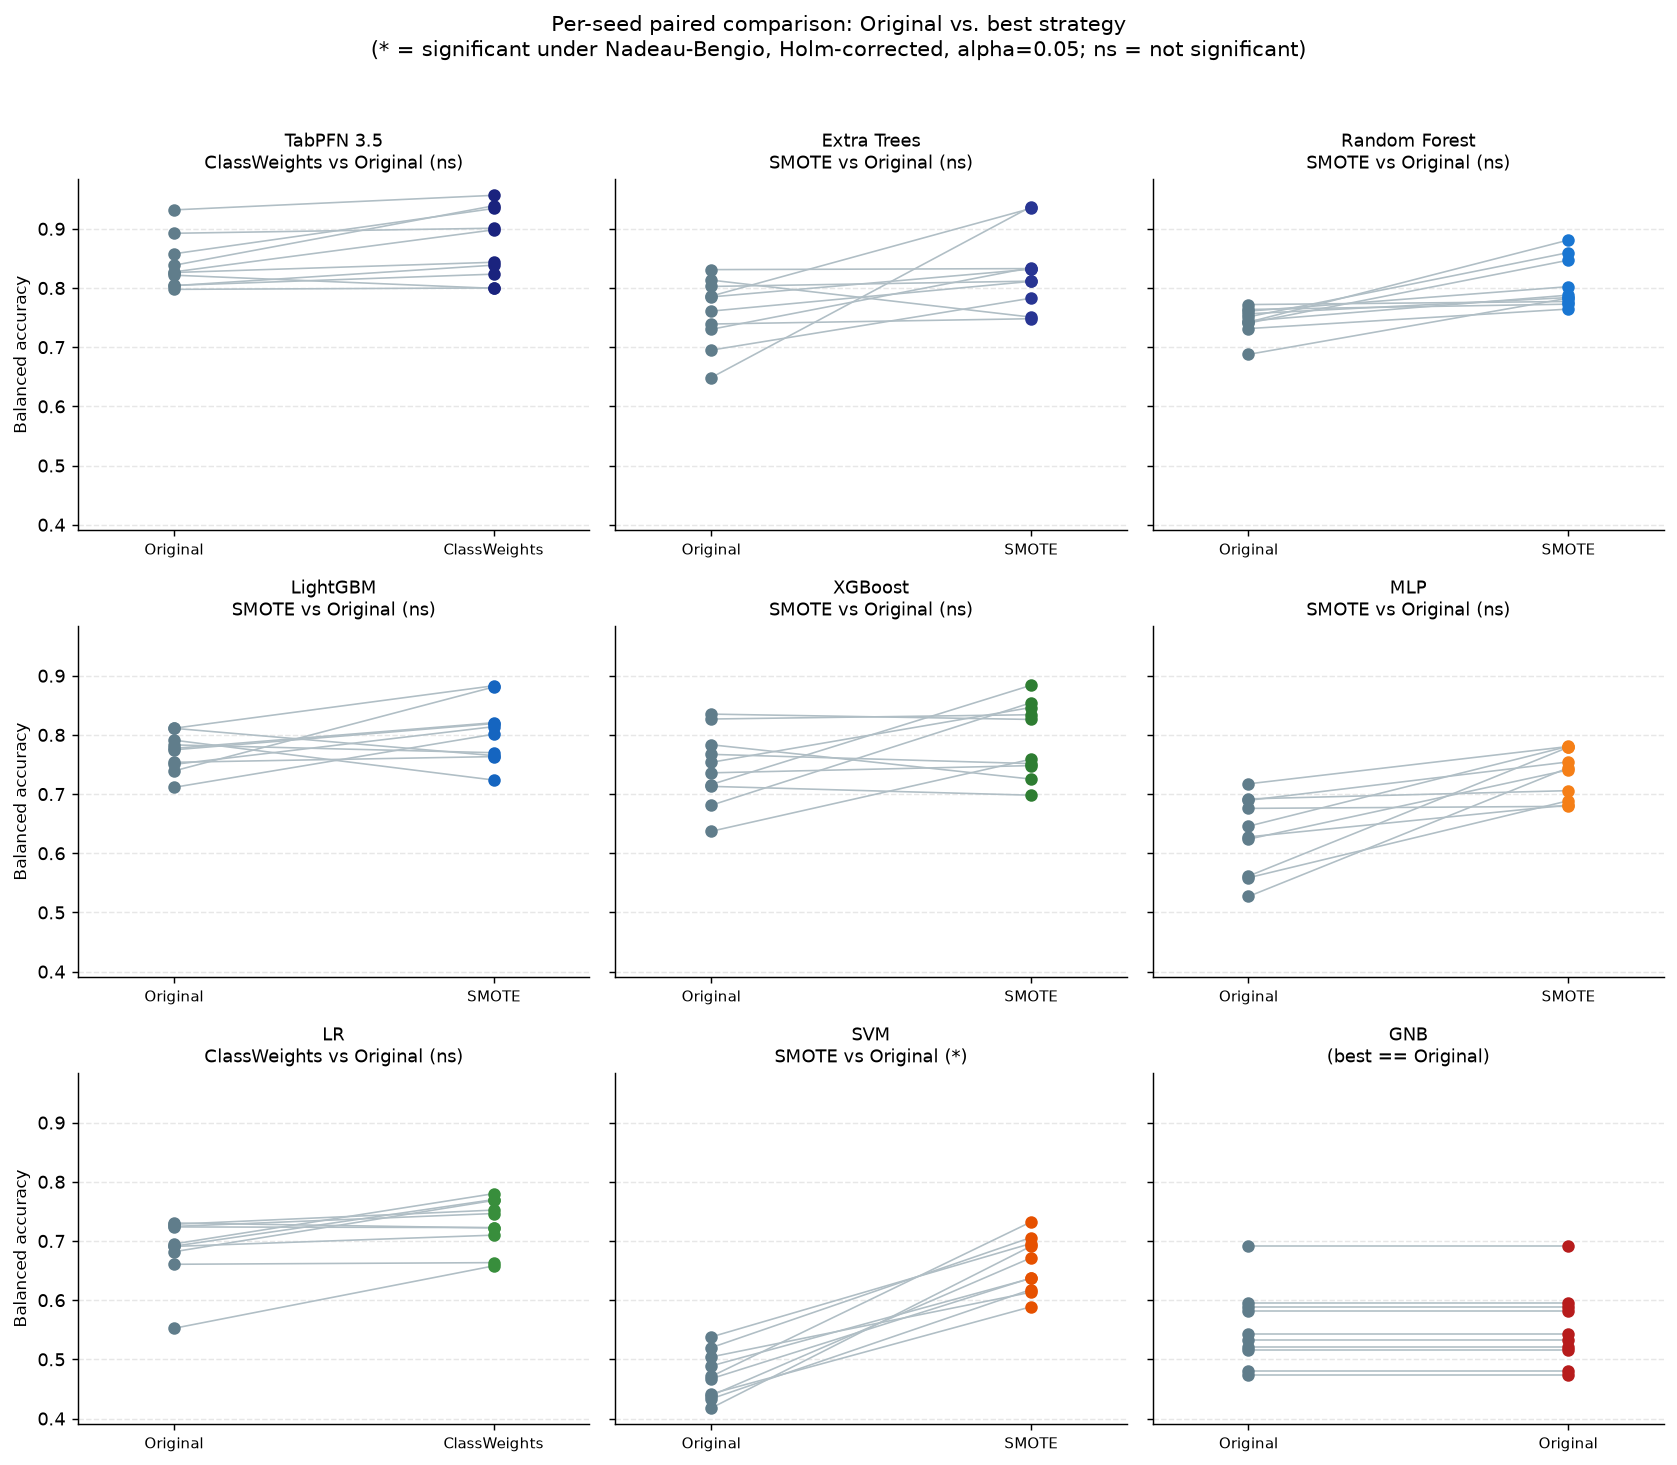

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharey=True)

for ax, (model_key, strategy, label) in zip(axes.flat, MODELS):
    o = orig_df[label].values
    b = best_df[label].values
    color = MODEL_COLORS.get(model_key, '#607d8b')

    for oi, bi in zip(o, b):
        ax.plot([0, 1], [oi, bi], color='#b0bec5', linewidth=0.9, zorder=1)
    ax.scatter(np.zeros(len(o)), o, color='#607d8b', s=35, zorder=2, label='Original')
    ax.scatter(np.ones(len(b)), b, color=color, s=35, zorder=2, label=strategy)

    row = result_df[result_df['Model'] == label].iloc[0]
    if strategy != 'Original':
        test_row = testable[testable['Model'] == label].iloc[0]
        sig_marker = '*' if test_row['Significant (NB)'] else 'ns'
        title = f"{label}\n{strategy} vs Original ({sig_marker})"
    else:
        title = f"{label}\n(best == Original)"
    ax.set_title(title, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Original', strategy], fontsize=8.5)
    ax.set_xlim(-0.3, 1.3)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel('Balanced accuracy', fontsize=9.5)

plt.suptitle('Per-seed paired comparison: Original vs. best strategy\n'
             '(* = significant under Nadeau-Bengio, Holm-corrected, alpha=0.05; ns = not significant)',
             fontsize=11.5, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'strategy_improvement_paired.png'), dpi=200, bbox_inches='tight')
plt.show()

## 5  Summary

In [7]:
n_sig_w = testable['Significant (Wilcoxon)'].sum()
n_sig_nb = testable['Significant (NB)'].sum()
n_both = (testable['Significant (Wilcoxon)'] & testable['Significant (NB)']).sum()

print('=' * 72)
print('WITHIN-MODEL STRATEGY IMPROVEMENT -- SUMMARY')
print('=' * 72)
print(f'\n8 models tested (GNB excluded: best strategy == Original)\n')
print(f'Significant under Wilcoxon (Holm):      {n_sig_w}/8')
print(f'Significant under Nadeau-Bengio (Holm): {n_sig_nb}/8')
print(f'Significant under BOTH tests:            {n_both}/8\n')

robust = testable[testable['Significant (Wilcoxon)'] & testable['Significant (NB)']]['Model'].tolist()
fragile = testable[~(testable['Significant (Wilcoxon)'] & testable['Significant (NB)']) &
                    (testable['Significant (Wilcoxon)'] | testable['Significant (NB)'])]['Model'].tolist()
not_sig = testable[~testable['Significant (Wilcoxon)'] & ~testable['Significant (NB)']]['Model'].tolist()

if robust:
    print(f'Robust improvement (both tests agree): {", ".join(robust)}')
if fragile:
    print(f'Borderline (tests disagree):           {", ".join(fragile)}')
if not_sig:
    print(f'Not statistically significant:         {", ".join(not_sig)}')
print()
print('Implication for the paper: claims about a specific strategy "improving" a model')
print('should be qualified by this table -- a raw mean gap alone, as currently reported')
print('in the Effects-of-class-imbalance section, does not establish that the gap is')
print('more than seed-to-seed noise for every model.')

WITHIN-MODEL STRATEGY IMPROVEMENT -- SUMMARY

8 models tested (GNB excluded: best strategy == Original)

Significant under Wilcoxon (Holm):      3/8
Significant under Nadeau-Bengio (Holm): 1/8
Significant under BOTH tests:            1/8

Robust improvement (both tests agree): SVM
Borderline (tests disagree):           Random Forest, MLP
Not statistically significant:         TabPFN 3.5, Extra Trees, LightGBM, XGBoost, LR

Implication for the paper: claims about a specific strategy "improving" a model
should be qualified by this table -- a raw mean gap alone, as currently reported
in the Effects-of-class-imbalance section, does not establish that the gap is
more than seed-to-seed noise for every model.
